# 01 — EDA de RDD2022 para detección de baches

**Proyecto:** Pothole Detection Guatemala

Este notebook analiza:
- distribución de imágenes por dominio;
- prevalencia de D40;
- desbalance de la tarea binaria;
- distribución de clases;
- imágenes sin daño anotado, con otros daños y con D40;
- tamaño relativo de bounding boxes D40;
- coocurrencia de D40 con otros tipos de daño;
- candidatos para `test_ood`.

La tarea supervisada principal será **presencia de D40 por imagen**:
- `1`: existe al menos un D40;
- `0`: no existe D40, aunque pueda existir otro tipo de daño.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_ROOT = PROJECT_ROOT / "data" / "raw" / "RDD2022"
MANIFEST_DIR = PROJECT_ROOT / "data" / "manifests"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

IMAGES_CSV = MANIFEST_DIR / "images.csv"
ANNOTATIONS_CSV = MANIFEST_DIR / "annotations.csv"

images = pd.read_csv(IMAGES_CSV)
annotations = pd.read_csv(ANNOTATIONS_CSV)

print("images:", images.shape)
print("annotations:", annotations.shape)

C:\Users\viank\AppData\Local\Temp\ipykernel_17692\1858863161.py:16: DtypeWarning: Columns (19) have mixed types. Specify dtype option on import or set low_memory=False.
  images = pd.read_csv(IMAGES_CSV)


images: (38385, 20)
annotations: (65712, 12)


## 1. Revisión rápida

In [3]:
display(images.head())
display(annotations.head())

assert len(images) == 38385
assert len(annotations) == 65712
assert images["sample_id"].is_unique

print("Manifests cargados correctamente.")

,sample_id,country,image_path,xml_path,width,height,depth,num_objects,num_D00,num_D10,num_D20,num_D40,has_D00,has_D10,has_D20,has_D40,has_any_damage,is_empty_annotation,has_other_label,other_labels
0,China_Drone__China_Drone_000000,China_Drone,China_Drone/China_Drone/train/images/China_Dro...,China_Drone/China_Drone/train/annotations/xmls...,512,512,3.0,1,0,1,0,0,0,1,0,0,1,0,0,NaN
1,China_Drone__China_Drone_000001,China_Drone,China_Drone/China_Drone/train/images/China_Dro...,China_Drone/China_Drone/train/annotations/xmls...,512,512,3.0,2,1,1,0,0,1,1,0,0,1,0,0,NaN
2,China_Drone__China_Drone_000002,China_Drone,China_Drone/China_Drone/train/images/China_Dro...,China_Drone/China_Drone/train/annotations/xmls...,512,512,3.0,2,2,0,0,0,1,0,0,0,1,0,0,NaN
3,China_Drone__China_Drone_000003,China_Drone,China_Drone/China_Drone/train/images/China_Dro...,China_Drone/China_Drone/train/annotations/xmls...,512,512,3.0,3,1,2,0,0,1,1,0,0,1,0,0,NaN
4,China_Drone__China_Drone_000004,China_Drone,China_Drone/China_Drone/train/images/China_Dro...,China_Drone/China_Drone/train/annotations/xmls...,512,512,3.0,2,0,1,1,0,0,1,1,0,1,0,0,NaN


,sample_id,country,object_index,class,xmin,ymin,xmax,ymax,bbox_width,bbox_height,bbox_area,bbox_area_ratio
0,China_Drone__China_Drone_000000,China_Drone,0,D10,323,213,390,245,67,32,2144,0.008179
1,China_Drone__China_Drone_000001,China_Drone,0,D10,14,70,198,99,184,29,5336,0.020355
2,China_Drone__China_Drone_000001,China_Drone,1,D00,95,114,120,272,25,158,3950,0.015068
3,China_Drone__China_Drone_000002,China_Drone,0,D00,12,214,68,511,56,297,16632,0.063446
4,China_Drone__China_Drone_000002,China_Drone,1,D00,60,1,112,212,52,211,10972,0.041855


Manifests cargados correctamente.


## 2. Resumen por dominio

In [4]:
country_summary = (
    images.groupby("country")
    .agg(
        total_images=("sample_id", "count"),
        images_with_D40=("has_D40", "sum"),
        images_with_damage=("has_any_damage", "sum"),
        empty_annotations=("is_empty_annotation", "sum"),
    )
    .reset_index()
)

country_summary["images_without_D40"] = (
    country_summary["total_images"] - country_summary["images_with_D40"]
)

country_summary["pothole_prevalence_pct"] = (
    100 * country_summary["images_with_D40"] / country_summary["total_images"]
)

country_summary = country_summary.sort_values(
    "total_images", ascending=False
).reset_index(drop=True)

country_summary

,country,total_images,images_with_D40,images_with_damage,empty_annotations,images_without_D40,pothole_prevalence_pct
0,Japan,10506,1390,9712,794,9116,13.230535
1,Norway,8161,256,2914,5247,7905,3.136870
2,India,7706,1530,3785,3921,6176,19.854659
3,United_States,4805,116,4805,0,4689,2.414152
4,Czech,2829,154,1072,1757,2675,5.443620
5,China_Drone,2401,64,2396,5,2337,2.665556
6,China_MotorBike,1977,164,1977,0,1813,8.295397


In [5]:
country_summary.to_csv(
    TABLE_DIR / "country_summary.csv",
    index=False
)

## 3. Imágenes de entrenamiento por dominio

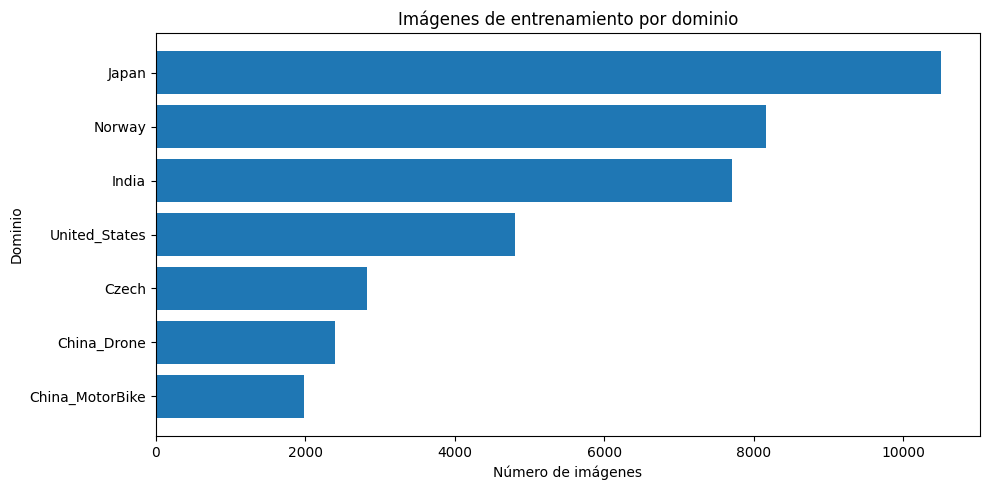

In [6]:
plot_df = country_summary.sort_values("total_images")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_df["country"], plot_df["total_images"])
ax.set_title("Imágenes de entrenamiento por dominio")
ax.set_xlabel("Número de imágenes")
ax.set_ylabel("Dominio")
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "01_images_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Prevalencia de potholes D40 por dominio

Una imagen puede contener más de un objeto D40, pero para la tarea binaria solo importa si existe **al menos uno**.

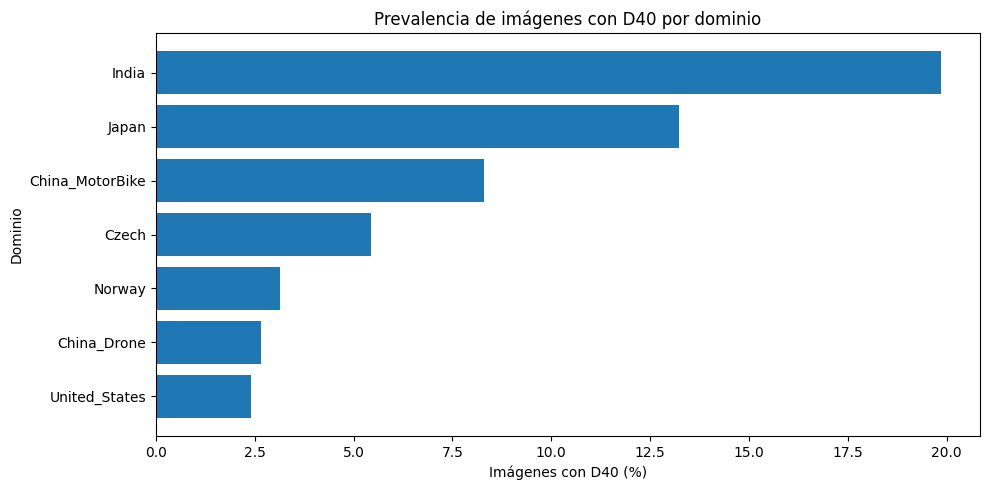

In [7]:
plot_df = country_summary.sort_values("pothole_prevalence_pct")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_df["country"], plot_df["pothole_prevalence_pct"])
ax.set_title("Prevalencia de imágenes con D40 por dominio")
ax.set_xlabel("Imágenes con D40 (%)")
ax.set_ylabel("Dominio")
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "02_d40_prevalence_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Desbalance global de la tarea binaria

Para clasificación de presencia de bache, el número de **imágenes positivas** es más importante que el número total de objetos D40.

Un conjunto desbalanceado **no significa que el modelo no pueda funcionar**. Significa que el entrenamiento y la evaluación deben diseñarse para evitar que el modelo aprenda a predecir casi siempre la clase mayoritaria.

In [8]:
positive_images = int(images["has_D40"].sum())
negative_images = int(len(images) - positive_images)
prevalence = positive_images / len(images)
neg_pos_ratio = negative_images / positive_images

imbalance_summary = pd.DataFrame({
    "group": ["D40", "No D40"],
    "images": [positive_images, negative_images],
    "percentage": [
        100 * positive_images / len(images),
        100 * negative_images / len(images),
    ],
})

display(imbalance_summary)

print(f"Positivas D40: {positive_images:,}")
print(f"Negativas: {negative_images:,}")
print(f"Prevalencia D40: {100*prevalence:.2f}%")
print(f"Relación negativas:positivas = {neg_pos_ratio:.2f}:1")

,group,images,percentage
0,D40,3674,9.571447
1,No D40,34711,90.428553


Positivas D40: 3,674
Negativas: 34,711
Prevalencia D40: 9.57%
Relación negativas:positivas = 9.45:1


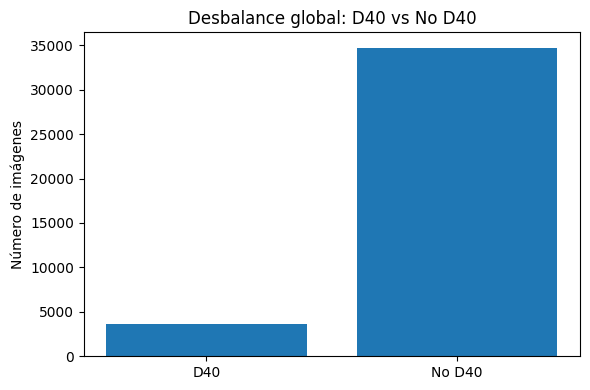

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(imbalance_summary["group"], imbalance_summary["images"])
ax.set_title("Desbalance global: D40 vs No D40")
ax.set_ylabel("Número de imágenes")
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "03_global_class_imbalance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Recomendación para manejar el desbalance

Para el experimento principal se recomienda:

1. **No rebalancear `validation`, `test_id`, `test_ood` ni Guatemala.** Deben conservar una distribución realista.
2. En `train`, comenzar con **transfer learning + pérdida ponderada**. Para una salida binaria con `BCEWithLogitsLoss`, un punto de partida natural es `pos_weight = N_neg / N_pos`.
3. Aplicar **data augmentation únicamente durante entrenamiento**, incluyendo transformaciones realistas de iluminación, blur moderado y condiciones de captura.
4. Comparar como ablation un `WeightedRandomSampler` o focal loss **solo si la pérdida ponderada no es suficiente**. No conviene apilar todas las técnicas desde el primer experimento.
5. Seleccionar el umbral de decisión usando **validation**, optimizando F1 o priorizando recall según el objetivo; no asumir que 0.50 es siempre óptimo.
6. Reportar **precision, recall, F1, PR-AUC y matriz de confusión**. Accuracy será secundaria.

Con 3,674 imágenes positivas antes de reservar OOD, el problema no es “demasiado pequeño” para transfer learning; el problema principal es el **desbalance y la variación entre dominios**.

In [10]:
suggested_pos_weight = negative_images / positive_images

print(
    "pos_weight global de referencia para BCEWithLogitsLoss:",
    round(suggested_pos_weight, 4)
)
print(
    "IMPORTANTE: recalcular este valor usando SOLO el train final "
    "después de crear splits."
)

pos_weight global de referencia para BCEWithLogitsLoss: 9.4477
IMPORTANTE: recalcular este valor usando SOLO el train final después de crear splits.


## 6. Objetos por clase

RDD2022 contiene etiquetas adicionales a las cuatro principales. Se muestran todas para preservar la información original.

In [11]:
class_counts = (
    annotations["class"]
    .value_counts()
    .rename_axis("class")
    .reset_index(name="objects")
)

class_counts

,class,objects
0,D00,26016
1,D10,11830
2,D20,10617
3,D40,6544
4,D44,5057
5,D50,3581
6,Repair,1046
7,D43,793
8,D01,179
9,D11,45


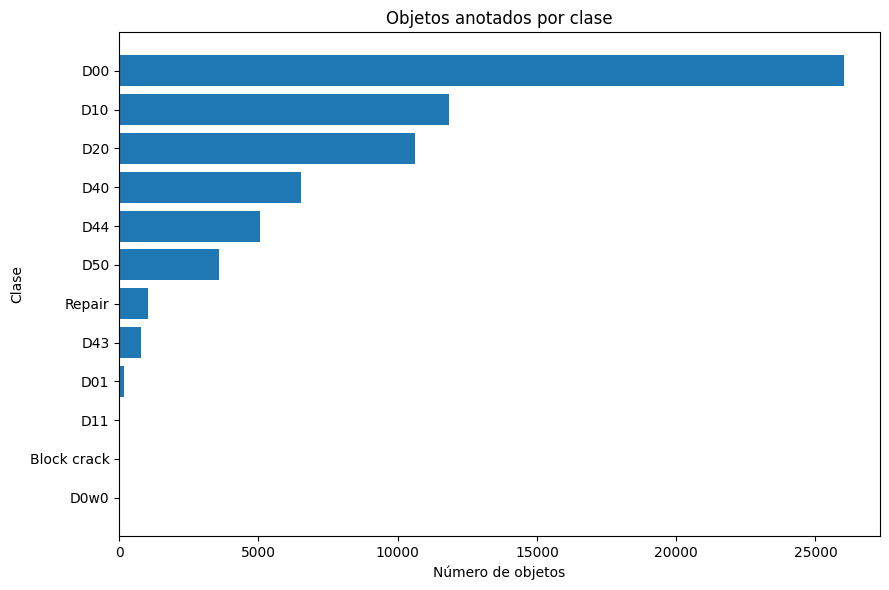

In [12]:
plot_df = class_counts.sort_values("objects")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df["class"], plot_df["objects"])
ax.set_title("Objetos anotados por clase")
ax.set_xlabel("Número de objetos")
ax.set_ylabel("Clase")
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "04_objects_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Clases principales y etiquetas adicionales

In [13]:
CANONICAL_CLASSES = {"D00", "D10", "D20", "D40"}

class_counts["category"] = np.where(
    class_counts["class"].isin(CANONICAL_CLASSES),
    "Principal",
    "Adicional",
)

display(class_counts)

print("Etiquetas adicionales:")
display(
    class_counts[class_counts["category"] == "Adicional"]
    .reset_index(drop=True)
)

,class,objects,category
0,D00,26016,Principal
1,D10,11830,Principal
2,D20,10617,Principal
3,D40,6544,Principal
4,D44,5057,Adicional
5,D50,3581,Adicional
6,Repair,1046,Adicional
7,D43,793,Adicional
8,D01,179,Adicional
9,D11,45,Adicional


Etiquetas adicionales:


,class,objects,category
0,D44,5057,Adicional
1,D50,3581,Adicional
2,Repair,1046,Adicional
3,D43,793,Adicional
4,D01,179,Adicional
5,D11,45,Adicional
6,Block crack,3,Adicional
7,D0w0,1,Adicional


## 8. Tres estados útiles para el VAE

Para el VAE no conviene tratar automáticamente todo `No D40` como “normal”.

Se separan tres grupos:
- **Pothole D40:** contiene al menos un D40.
- **Other damage:** no contiene D40, pero sí al menos un objeto anotado.
- **No annotated damage:** XML sin objetos anotados.

El último grupo es el mejor candidato inicial para entrenamiento del VAE como “normal”, aunque en el informe debe llamarse **sin daño anotado** para no afirmar más de lo que las etiquetas garantizan.

In [14]:
conditions = [
    images["has_D40"] == 1,
    (images["has_D40"] == 0) & (images["has_any_damage"] == 1),
    images["has_any_damage"] == 0,
]

labels = [
    "Pothole D40",
    "Other damage",
    "No annotated damage",
]

images = images.copy()
images["road_status"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

road_status_counts = (
    images["road_status"]
    .value_counts()
    .rename_axis("road_status")
    .reset_index(name="images")
)

road_status_counts

,road_status,images
0,Other damage,22987
1,No annotated damage,11724
2,Pothole D40,3674


In [15]:
status_by_country = pd.crosstab(
    images["country"],
    images["road_status"],
)

status_by_country

road_status,No annotated damage,Other damage,Pothole D40
country,,,
China_Drone,5,2332,64
China_MotorBike,0,1813,164
Czech,1757,918,154
India,3921,2255,1530
Japan,794,8322,1390
Norway,5247,2658,256
United_States,0,4689,116


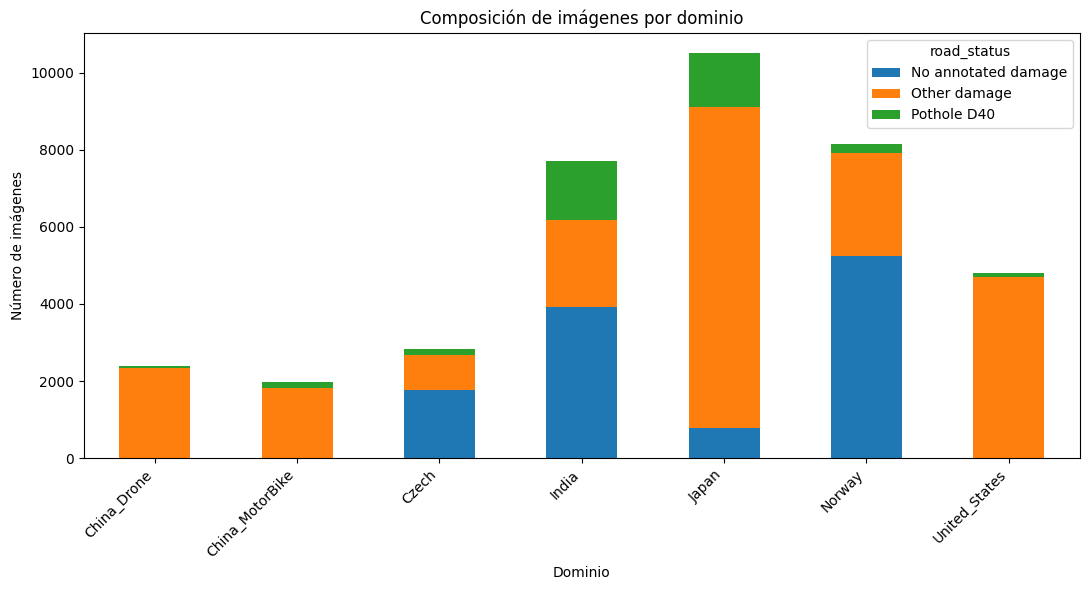

In [16]:
status_by_country.to_csv(
    TABLE_DIR / "road_status_by_country.csv"
)

ax = status_by_country.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
)

ax.set_title("Composición de imágenes por dominio")
ax.set_xlabel("Dominio")
ax.set_ylabel("Número de imágenes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_road_status_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Análisis específico de D40

In [17]:
d40 = annotations[
    annotations["class"] == "D40"
].copy()

print("Objetos D40:", len(d40))
print("Imágenes diferentes con D40:", d40["sample_id"].nunique())

display(d40["bbox_area_ratio"].describe())

Objetos D40: 6544
Imágenes diferentes con D40: 3674


count    6544.000000
mean        0.015325
std         0.030580
min         0.000027
25%         0.002450
50%         0.005377
75%         0.013611
max         0.387133
Name: bbox_area_ratio, dtype: float64

## 10. Tamaño relativo de los baches

`bbox_area_ratio` representa el área del bounding box dividida por el área total de la imagen. Esto permite comparar dominios con diferentes resoluciones.

In [18]:
d40_bbox_summary = (
    d40.groupby("country")
    .agg(
        d40_objects=("class", "count"),
        d40_images=("sample_id", "nunique"),
        mean_bbox_ratio=("bbox_area_ratio", "mean"),
        median_bbox_ratio=("bbox_area_ratio", "median"),
    )
    .reset_index()
)

d40_bbox_summary

,country,d40_objects,d40_images,mean_bbox_ratio,median_bbox_ratio
0,China_Drone,86,64,0.016973,0.008675
1,China_MotorBike,235,164,0.011885,0.002136
2,Czech,197,154,0.005824,0.004050
3,India,3187,1530,0.022895,0.008690
4,Japan,2243,1390,0.009317,0.004667
5,Norway,461,256,0.001369,0.000460
6,United_States,135,116,0.002890,0.001951


C:\Users\viank\AppData\Local\Temp\ipykernel_17692\3540596898.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels_box, showfliers=False)


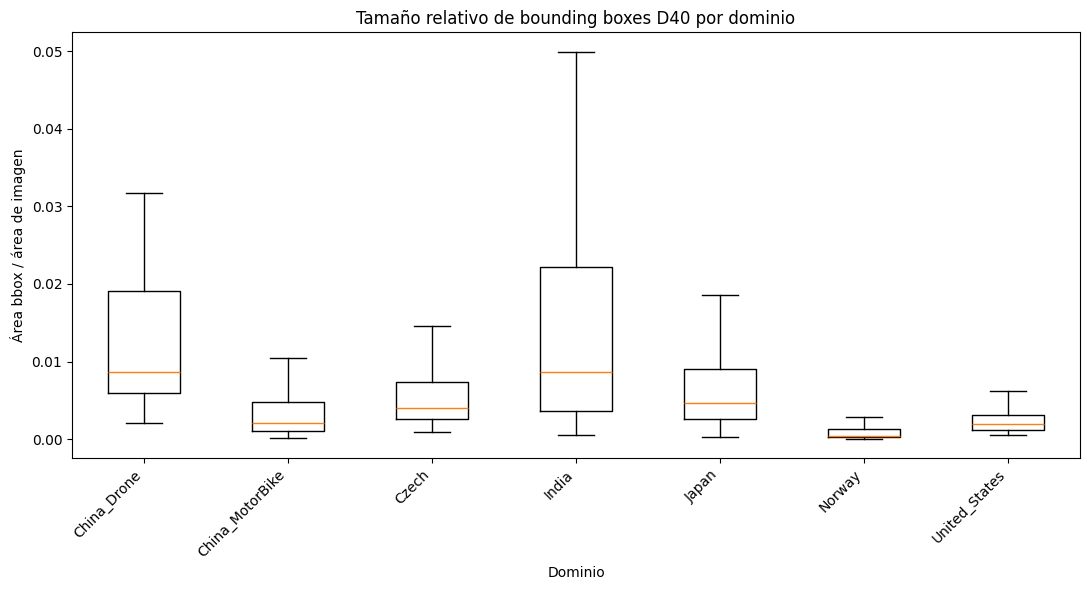

In [19]:
groups = []
labels_box = []

for country, group in d40.groupby("country"):
    values = group["bbox_area_ratio"].dropna().to_numpy()

    if len(values) > 0:
        groups.append(values)
        labels_box.append(country)

fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot(groups, labels=labels_box, showfliers=False)
ax.set_title("Tamaño relativo de bounding boxes D40 por dominio")
ax.set_xlabel("Dominio")
ax.set_ylabel("Área bbox / área de imagen")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "06_d40_bbox_size_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Coocurrencia de D40 con otros daños principales

Este análisis ayuda a detectar si una imagen con bache también suele contener grietas. Esto será útil al interpretar falsos positivos y Grad-CAM.

In [20]:
positive = images[images["has_D40"] == 1].copy()

cooccurrence = pd.DataFrame({
    "other_class": ["D00", "D10", "D20"],
    "images_with_D40_and_class": [
        int(((positive["has_D00"] == 1)).sum()),
        int(((positive["has_D10"] == 1)).sum()),
        int(((positive["has_D20"] == 1)).sum()),
    ],
})

cooccurrence["pct_of_D40_images"] = (
    100
    * cooccurrence["images_with_D40_and_class"]
    / len(positive)
)

cooccurrence

,other_class,images_with_D40_and_class,pct_of_D40_images
0,D00,870,23.679913
1,D10,385,10.479042
2,D20,1543,41.997823


## 12. Tabla para seleccionar el dominio OOD

La selección del país OOD no debe basarse solo en “qué país parece interesante”. Debe considerar al menos:
- número de imágenes;
- número de positivos D40;
- prevalencia;
- cantidad de imágenes sin daño anotado;
- tamaño de D40;
- modalidad de captura.

`China_Drone` debe evaluarse con cuidado porque introduce un cambio de perspectiva además del cambio geográfico.

In [21]:
ood_analysis = (
    country_summary
    .merge(
        d40_bbox_summary,
        on="country",
        how="left"
    )
)

ood_analysis = ood_analysis[
    [
        "country",
        "total_images",
        "images_with_D40",
        "images_without_D40",
        "pothole_prevalence_pct",
        "empty_annotations",
        "d40_objects",
        "median_bbox_ratio",
    ]
].sort_values(
    "pothole_prevalence_pct",
    ascending=False,
)

ood_analysis

,country,total_images,images_with_D40,images_without_D40,pothole_prevalence_pct,empty_annotations,d40_objects,median_bbox_ratio
2,India,7706,1530,6176,19.854659,3921,3187,0.008690
0,Japan,10506,1390,9116,13.230535,794,2243,0.004667
6,China_MotorBike,1977,164,1813,8.295397,0,235,0.002136
4,Czech,2829,154,2675,5.443620,1757,197,0.004050
1,Norway,8161,256,7905,3.136870,5247,461,0.000460
5,China_Drone,2401,64,2337,2.665556,5,86,0.008675
3,United_States,4805,116,4689,2.414152,0,135,0.001951


In [22]:
ood_analysis.to_csv(
    TABLE_DIR / "ood_candidate_analysis.csv",
    index=False
)

## 13. Muestra visual de imágenes D40 y No D40

Esta celda sirve para inspección cualitativa. No cambia los datos.

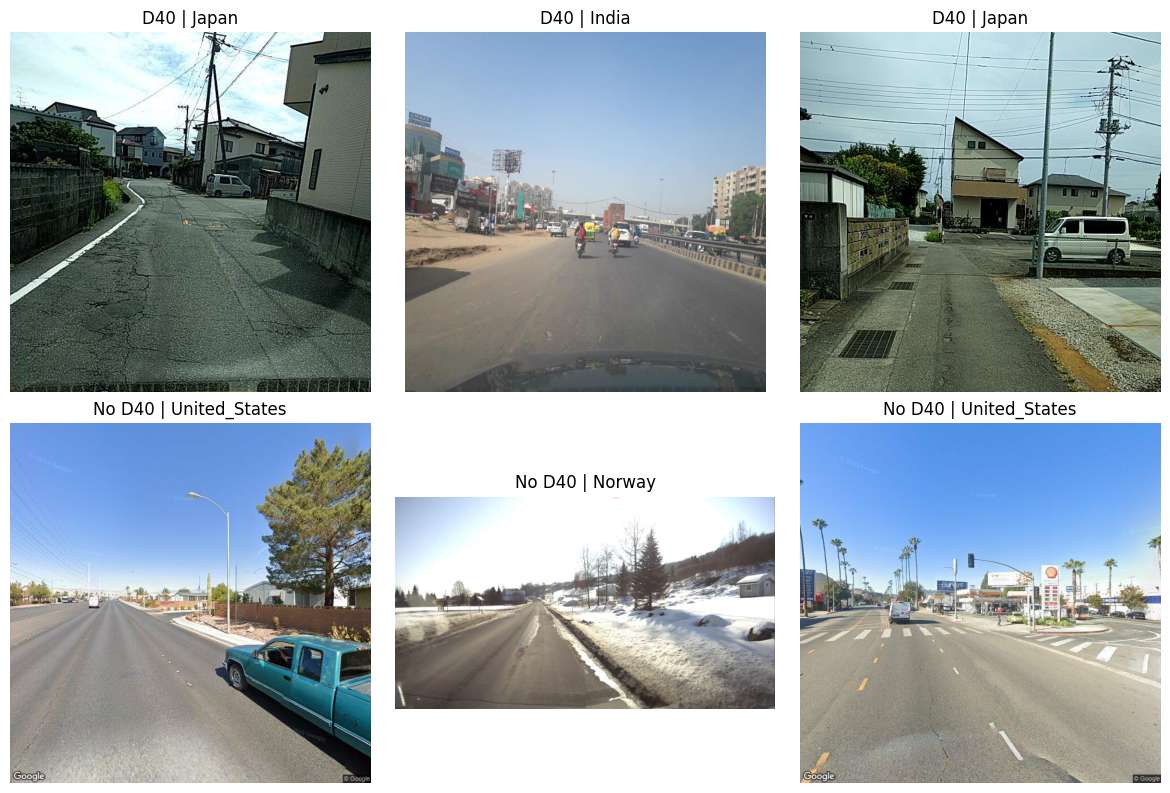

In [23]:
from PIL import Image

rng = 42

positives = images[images["has_D40"] == 1].sample(
    n=min(3, int((images["has_D40"] == 1).sum())),
    random_state=rng
)

negatives = images[images["has_D40"] == 0].sample(
    n=min(3, int((images["has_D40"] == 0).sum())),
    random_state=rng
)

sample_df = pd.concat([
    positives.assign(group="D40"),
    negatives.assign(group="No D40")
], ignore_index=True)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    image_path = DATASET_ROOT / row["image_path"]
    img = Image.open(image_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f'{row["group"]} | {row["country"]}')
    ax.axis("off")

for ax in axes[len(sample_df):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 14. Conclusiones del EDA

Al terminar este notebook, documentar:

1. nivel de desbalance global y por dominio;
2. dominios con mayor y menor prevalencia D40;
3. si el tamaño relativo de los baches cambia entre dominios;
4. disponibilidad de imágenes sin daño anotado para el VAE;
5. etiquetas adicionales presentes en RDD2022;
6. candidato(s) razonables para `test_ood`;
7. decisión sobre `China_Drone` para el experimento principal.

**No crear los splits finales antes de cerrar estas decisiones.**